In [6]:
!unzip -q PCB_Dataset.zip -d /content
!ls /content/PCB_Dataset

Defective  Good


Found 600 files belonging to 2 classes.
Using 480 files for training.
Found 600 files belonging to 2 classes.
Using 120 files for validation.
Classes: ['Defective', 'Good']


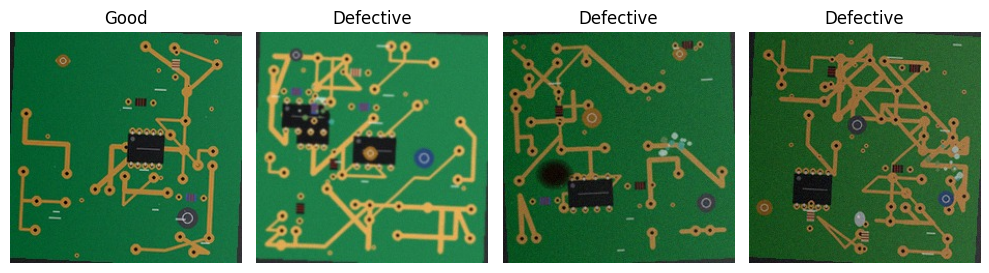

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 36s 258ms/step - accuracy: 0.5167 - loss: 0.8430 - val_accuracy: 0.5000 - val_loss: 0.7345
Epoch 2/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 29s 239ms/step - accuracy: 0.4729 - loss: 0.8907 - val_accuracy: 0.5083 - val_loss: 0.7271
Epoch 3/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 28s 235ms/step - accuracy: 0.5208 - loss: 0.8353 - val_accuracy: 0.5250 - val_loss: 0.7253
Epoch 4/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 28s 234ms/step - accuracy: 0.5125 - loss: 0.8289 - val_accuracy: 0.5333 - val_loss: 0.7194
Epoch 5/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 42s 246ms/step - accuracy: 0.5583 - loss: 0.7640 - val_accuracy: 0.5417 - val_loss: 0.7137
Epoch 6/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 29s 240ms/step - accuracy: 0.5188 - loss: 0.7978 - val_accuracy: 0.5500 - val_loss: 0.7081
Epoch 7/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 29s 245ms/step - accuracy: 0.5250 - loss: 0.7718 - val_accuracy: 0.5417 - val_loss: 0.7068
Epoch 8/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 28s 236ms/step - accuracy: 0.4812 - loss: 0

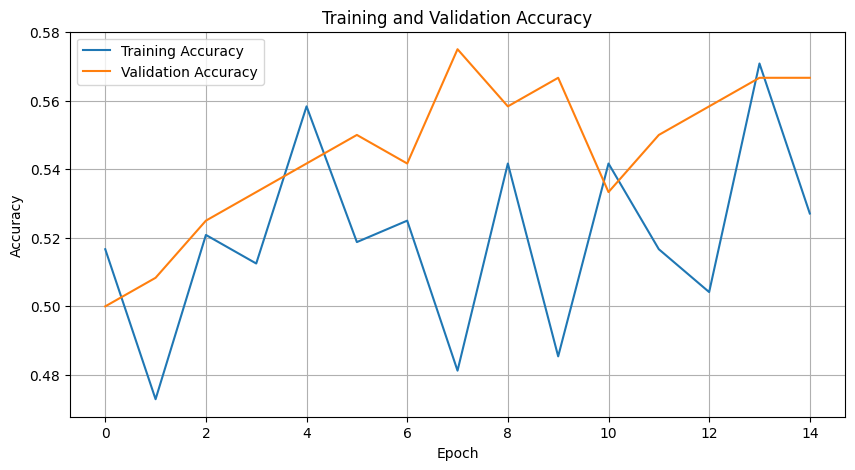

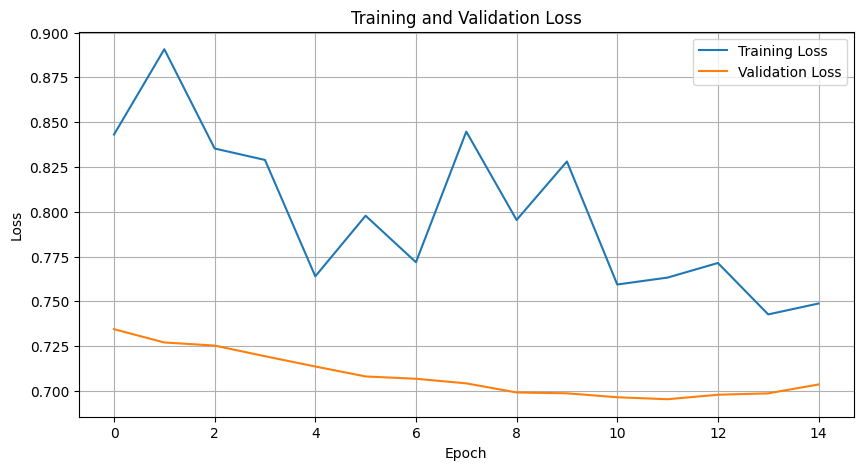

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Defective       0.61      0.41      0.49        61
        Good       0.54      0.73      0.62        59

    accuracy                           0.57       120
   macro avg       0.58      0.57      0.56       120
weighted avg       0.58      0.57      0.56       120



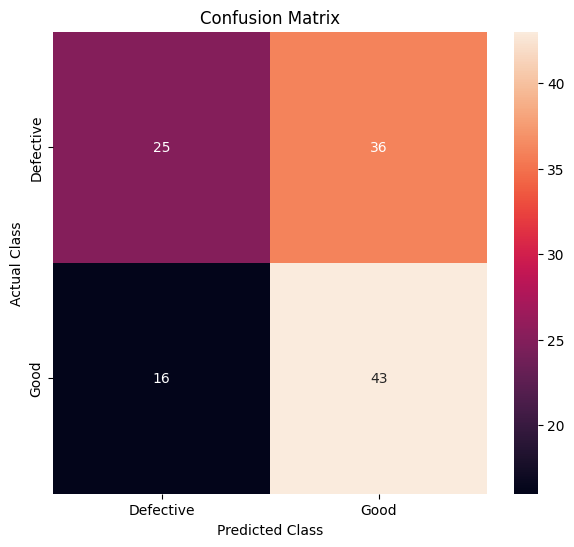

Upload a PCB image for prediction:


Saving Defect_Detected_4-2.webp to Defect_Detected_4-2.webp

PCB DEFECT DETECTION SYSTEM
----------------------------
Image        : Defect_Detected_4-2.webp
Detected PCB : Defective
Confidence   : 58.72 %

Model saved successfully!


In [7]:
# ============================================
# PCB DEFECT DETECTION USING CNN
# MobileNetV2 Transfer Learning
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from PIL import Image
from google.colab import files


# ============================================
# 1. LOAD DATASET
# ============================================

dataset_dir = "/content/PCB_Dataset"

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.20,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=4,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.20,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=4,
    label_mode="categorical"
)

class_names = train_ds.class_names

print("Classes:", class_names)


# ============================================
# 2. SHOW SAMPLE IMAGES
# ============================================

plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================
# 3. DATA AUGMENTATION
# ============================================

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.10)
])


# ============================================
# 4. MOBILE NET V2
# ============================================

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False


# ============================================
# 5. MODEL ARCHITECTURE
# ============================================

inputs = keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

x = preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    2,
    activation="softmax"
)(x)

model = keras.Model(
    inputs,
    outputs
)

model.summary()


# ============================================
# 6. MODEL COMPILATION
# ============================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================
# 7. MODEL TRAINING
# ============================================

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)


# ============================================
# 8. ACCURACY GRAPH
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()


# ============================================
# 9. LOSS GRAPH
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()


# ============================================
# 10. PREDICTIONS
# ============================================

y_true = []
y_pred = []

for images, labels in val_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    y_true.extend(
        np.argmax(
            labels.numpy(),
            axis=1
        )
    )

    y_pred.extend(
        np.argmax(
            predictions,
            axis=1
        )
    )


# ============================================
# 11. CLASSIFICATION REPORT
# ============================================

print("CLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)


# ============================================
# 12. CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.show()


# ============================================
# 13. PREDICTION FUNCTION
# ============================================

def predict_pcb(image):

    image = image.convert("RGB")

    image = image.resize(
        (224, 224)
    )

    img_array = np.array(image)

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    prediction = model.predict(
        img_array,
        verbose=0
    )[0]

    predicted_index = np.argmax(
        prediction
    )

    predicted_class = class_names[
        predicted_index
    ]

    confidence = (
        prediction[predicted_index] * 100
    )

    return predicted_class, confidence


# ============================================
# 14. UPLOAD PCB IMAGE FOR TESTING
# ============================================

print("Upload a PCB image for prediction:")

uploaded = files.upload()

for filename in uploaded:

    image = Image.open(filename)

    predicted_class, confidence = predict_pcb(
        image
    )

    print()
    print("PCB DEFECT DETECTION SYSTEM")
    print("----------------------------")
    print("Image        :", filename)
    print("Detected PCB :", predicted_class)
    print(
        "Confidence   :",
        round(confidence, 2),
        "%"
    )


# ============================================
# 15. SAVE MODEL
# ============================================

model.save(
    "/content/pcb_defect_detection_model.keras"
)

print()
print("Model saved successfully!")